# 04 - Held-out Evaluation and Demonstration

Everything below is computed from the saved test predictions; no model is
re-fitted here, so the numbers match the report exactly.

In [1]:
import os, sys, pathlib
root = pathlib.Path.cwd()
while not (root / "src" / "config.py").exists():
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)          # relative paths in the notebooks resolve from the root
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 160)
print("project root:", root)

project root: /home/shreyas/projects/dry-bean-classification


## 1. Model comparison on the test set

In [2]:
table = pd.read_csv("results/model_comparison.csv")
table[["label", "accuracy", "precision_macro", "recall_macro", "f1_macro",
       "f1_weighted", "roc_auc_ovr_macro", "predict_time_ms"]]

,label,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,predict_time_ms
0,RBF-SVM,0.9258,0.9383,0.9362,0.9372,0.9258,0.9953,167.4135
1,Hist Gradient Boosting,0.9229,0.9368,0.9328,0.9347,0.9229,0.9948,11.0872
2,Logistic Regression,0.9214,0.9357,0.9323,0.9337,0.9217,0.9949,0.6081
3,Extra Trees,0.9207,0.9356,0.9306,0.9328,0.9208,0.9943,71.9351
4,Random Forest,0.9196,0.9334,0.9297,0.9314,0.9195,0.9936,51.5085
5,K-Nearest Neighbours,0.9174,0.9328,0.9279,0.9300,0.9175,0.9870,19.4055


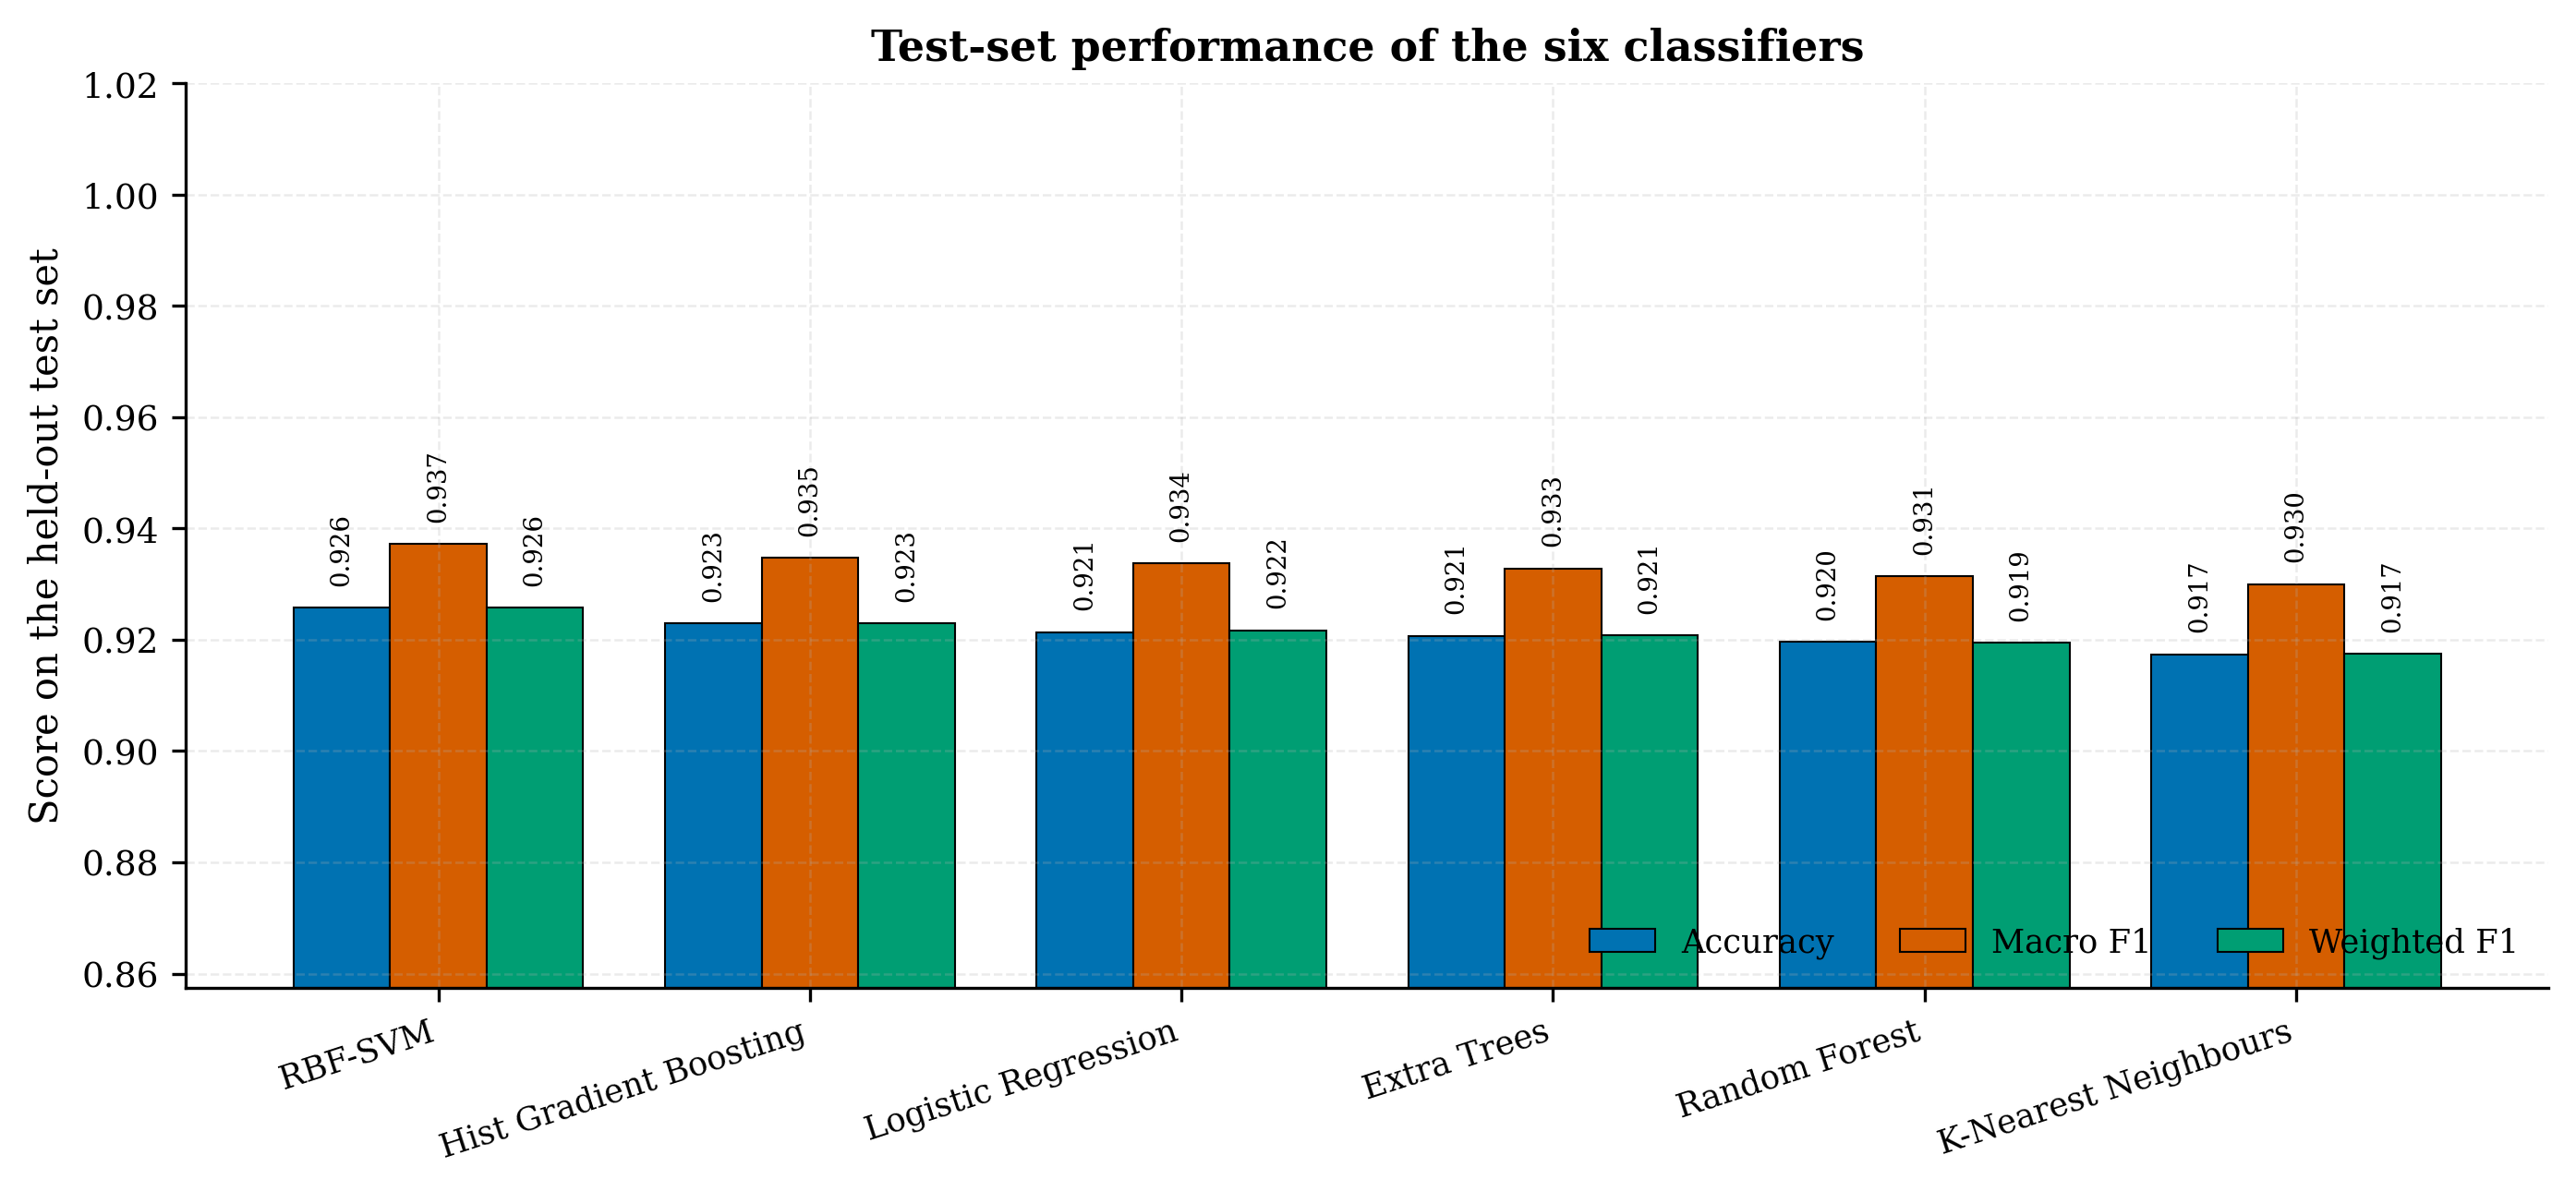

In [3]:
from IPython.display import Image, display
display(Image("figures/evaluation/fig_6_1_model_comparison.png", width=820))

## 2. Best model: confusion matrix and per-class scores

In [4]:
import json, numpy as np
meta = json.loads(open("results/experiment_metadata.json").read())
best = meta["best_model"]; print(best, "-", meta["best_model_label"])

svm_rbf - RBF-SVM


In [5]:
from src.preprocessing import load_split
from sklearn.metrics import classification_report
split = load_split()
y_pred = np.load(f"results/predictions/y_pred_{best}.npy")
print(classification_report(split.y_test, y_pred, digits=4))

              precision    recall  f1-score   support

    BARBUNYA     0.9308    0.9132    0.9219       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9385    0.9356    0.9370       326
    DERMASON     0.9147    0.9224    0.9185       709
       HOROZ     0.9683    0.9508    0.9595       386
       SEKER     0.9466    0.9606    0.9535       406
        SIRA     0.8693    0.8710    0.8701       527

    accuracy                         0.9258      2723
   macro avg     0.9383    0.9362    0.9372      2723
weighted avg     0.9259    0.9258    0.9258      2723



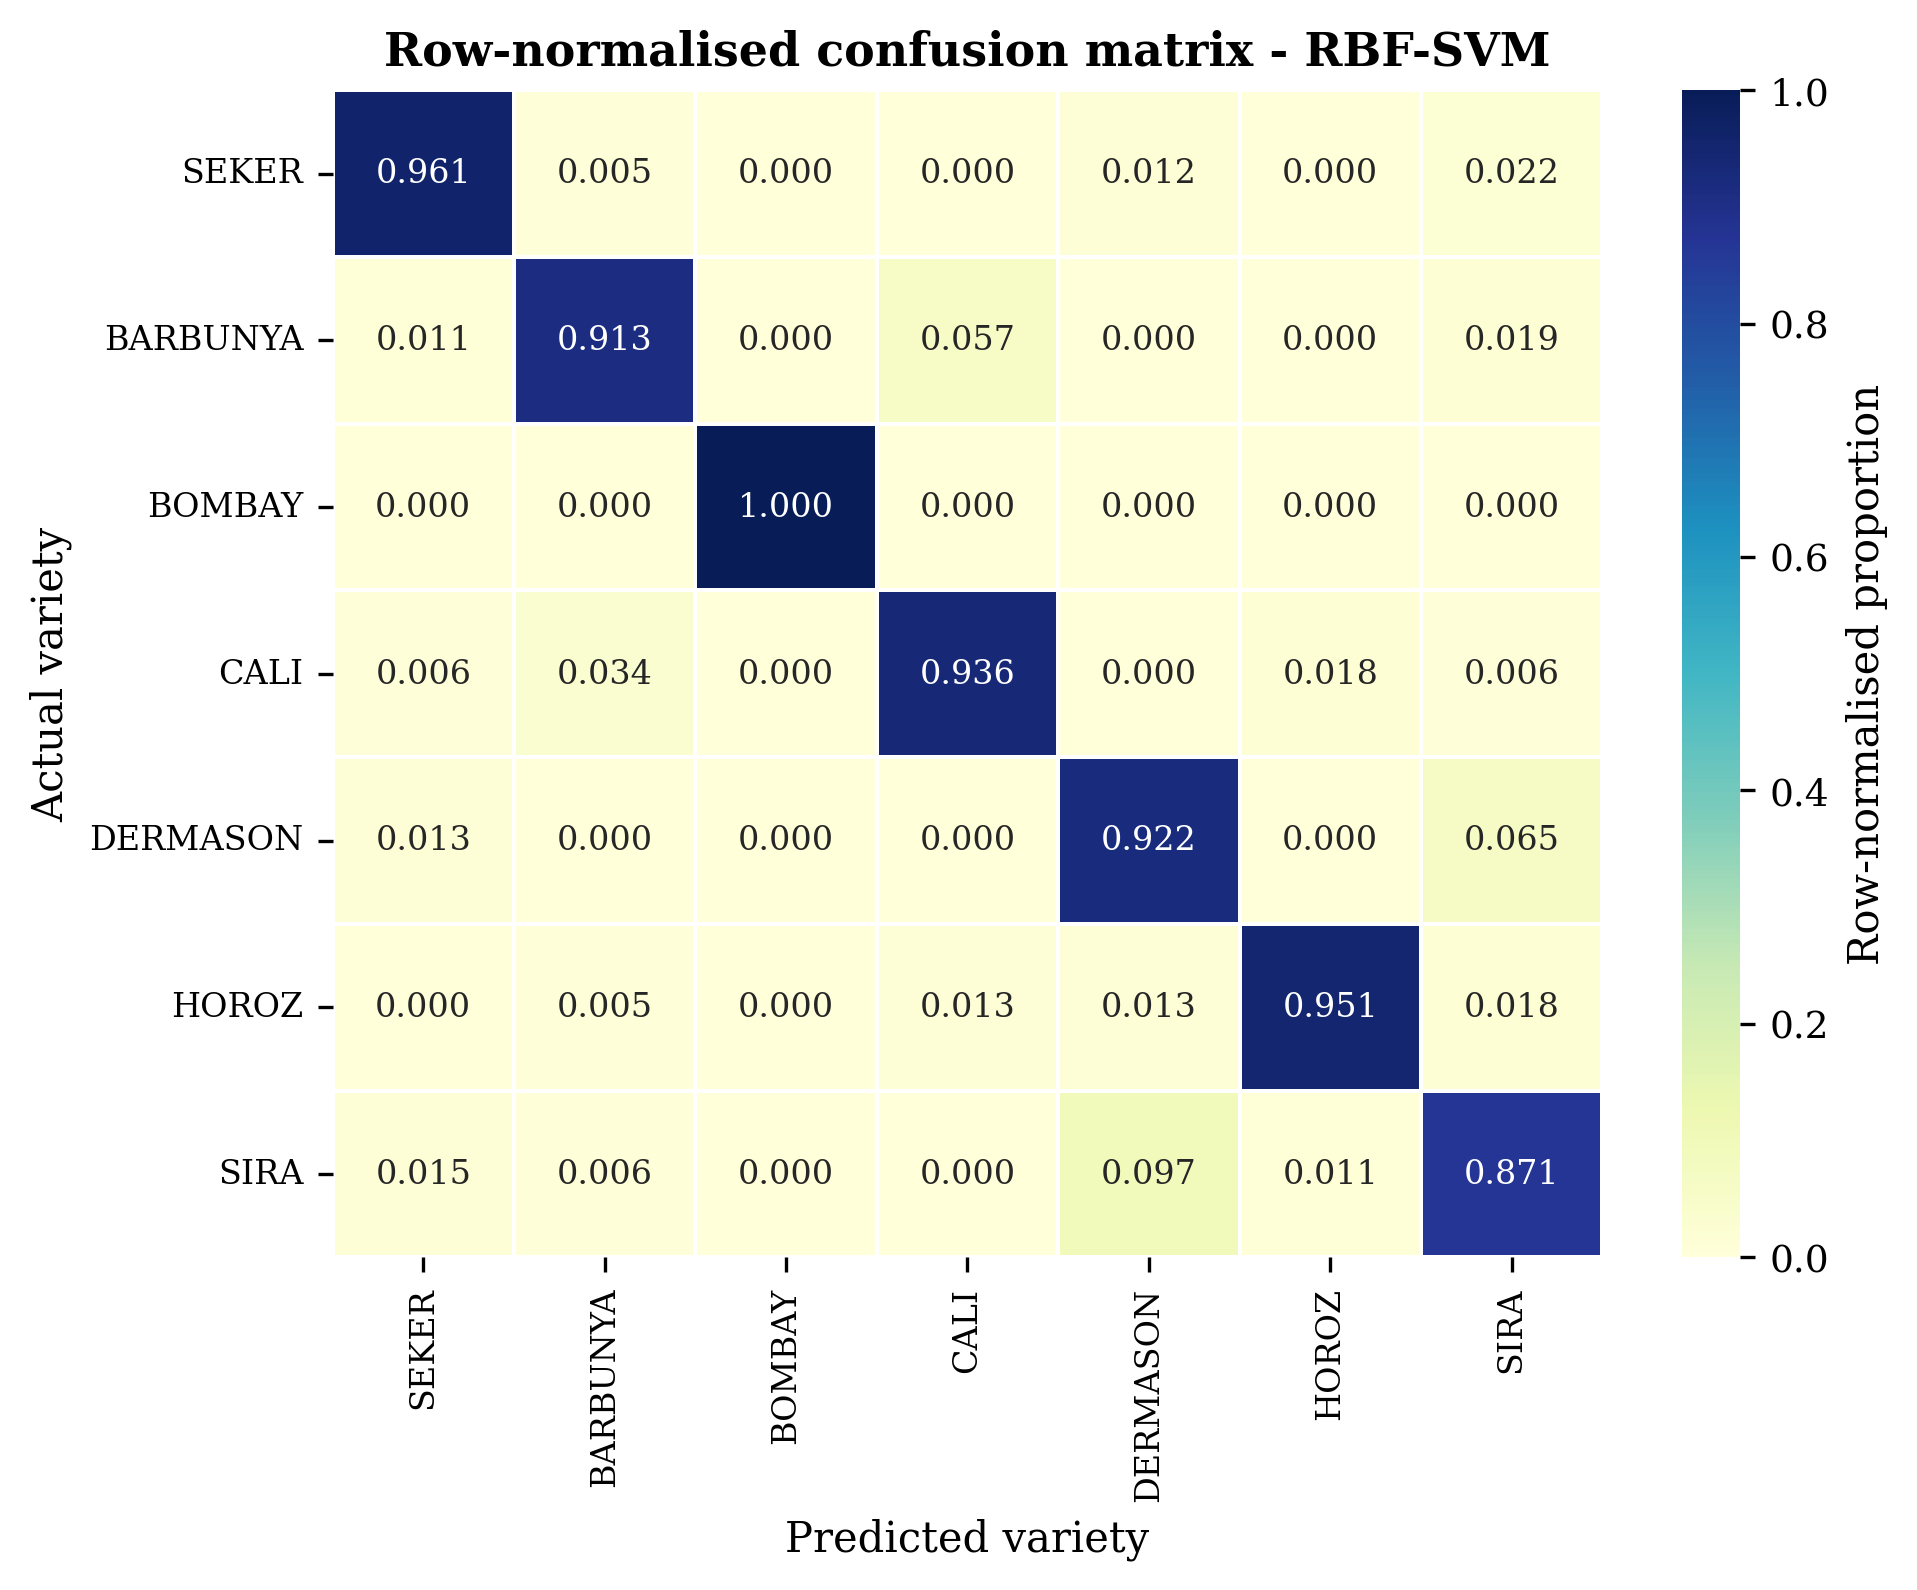

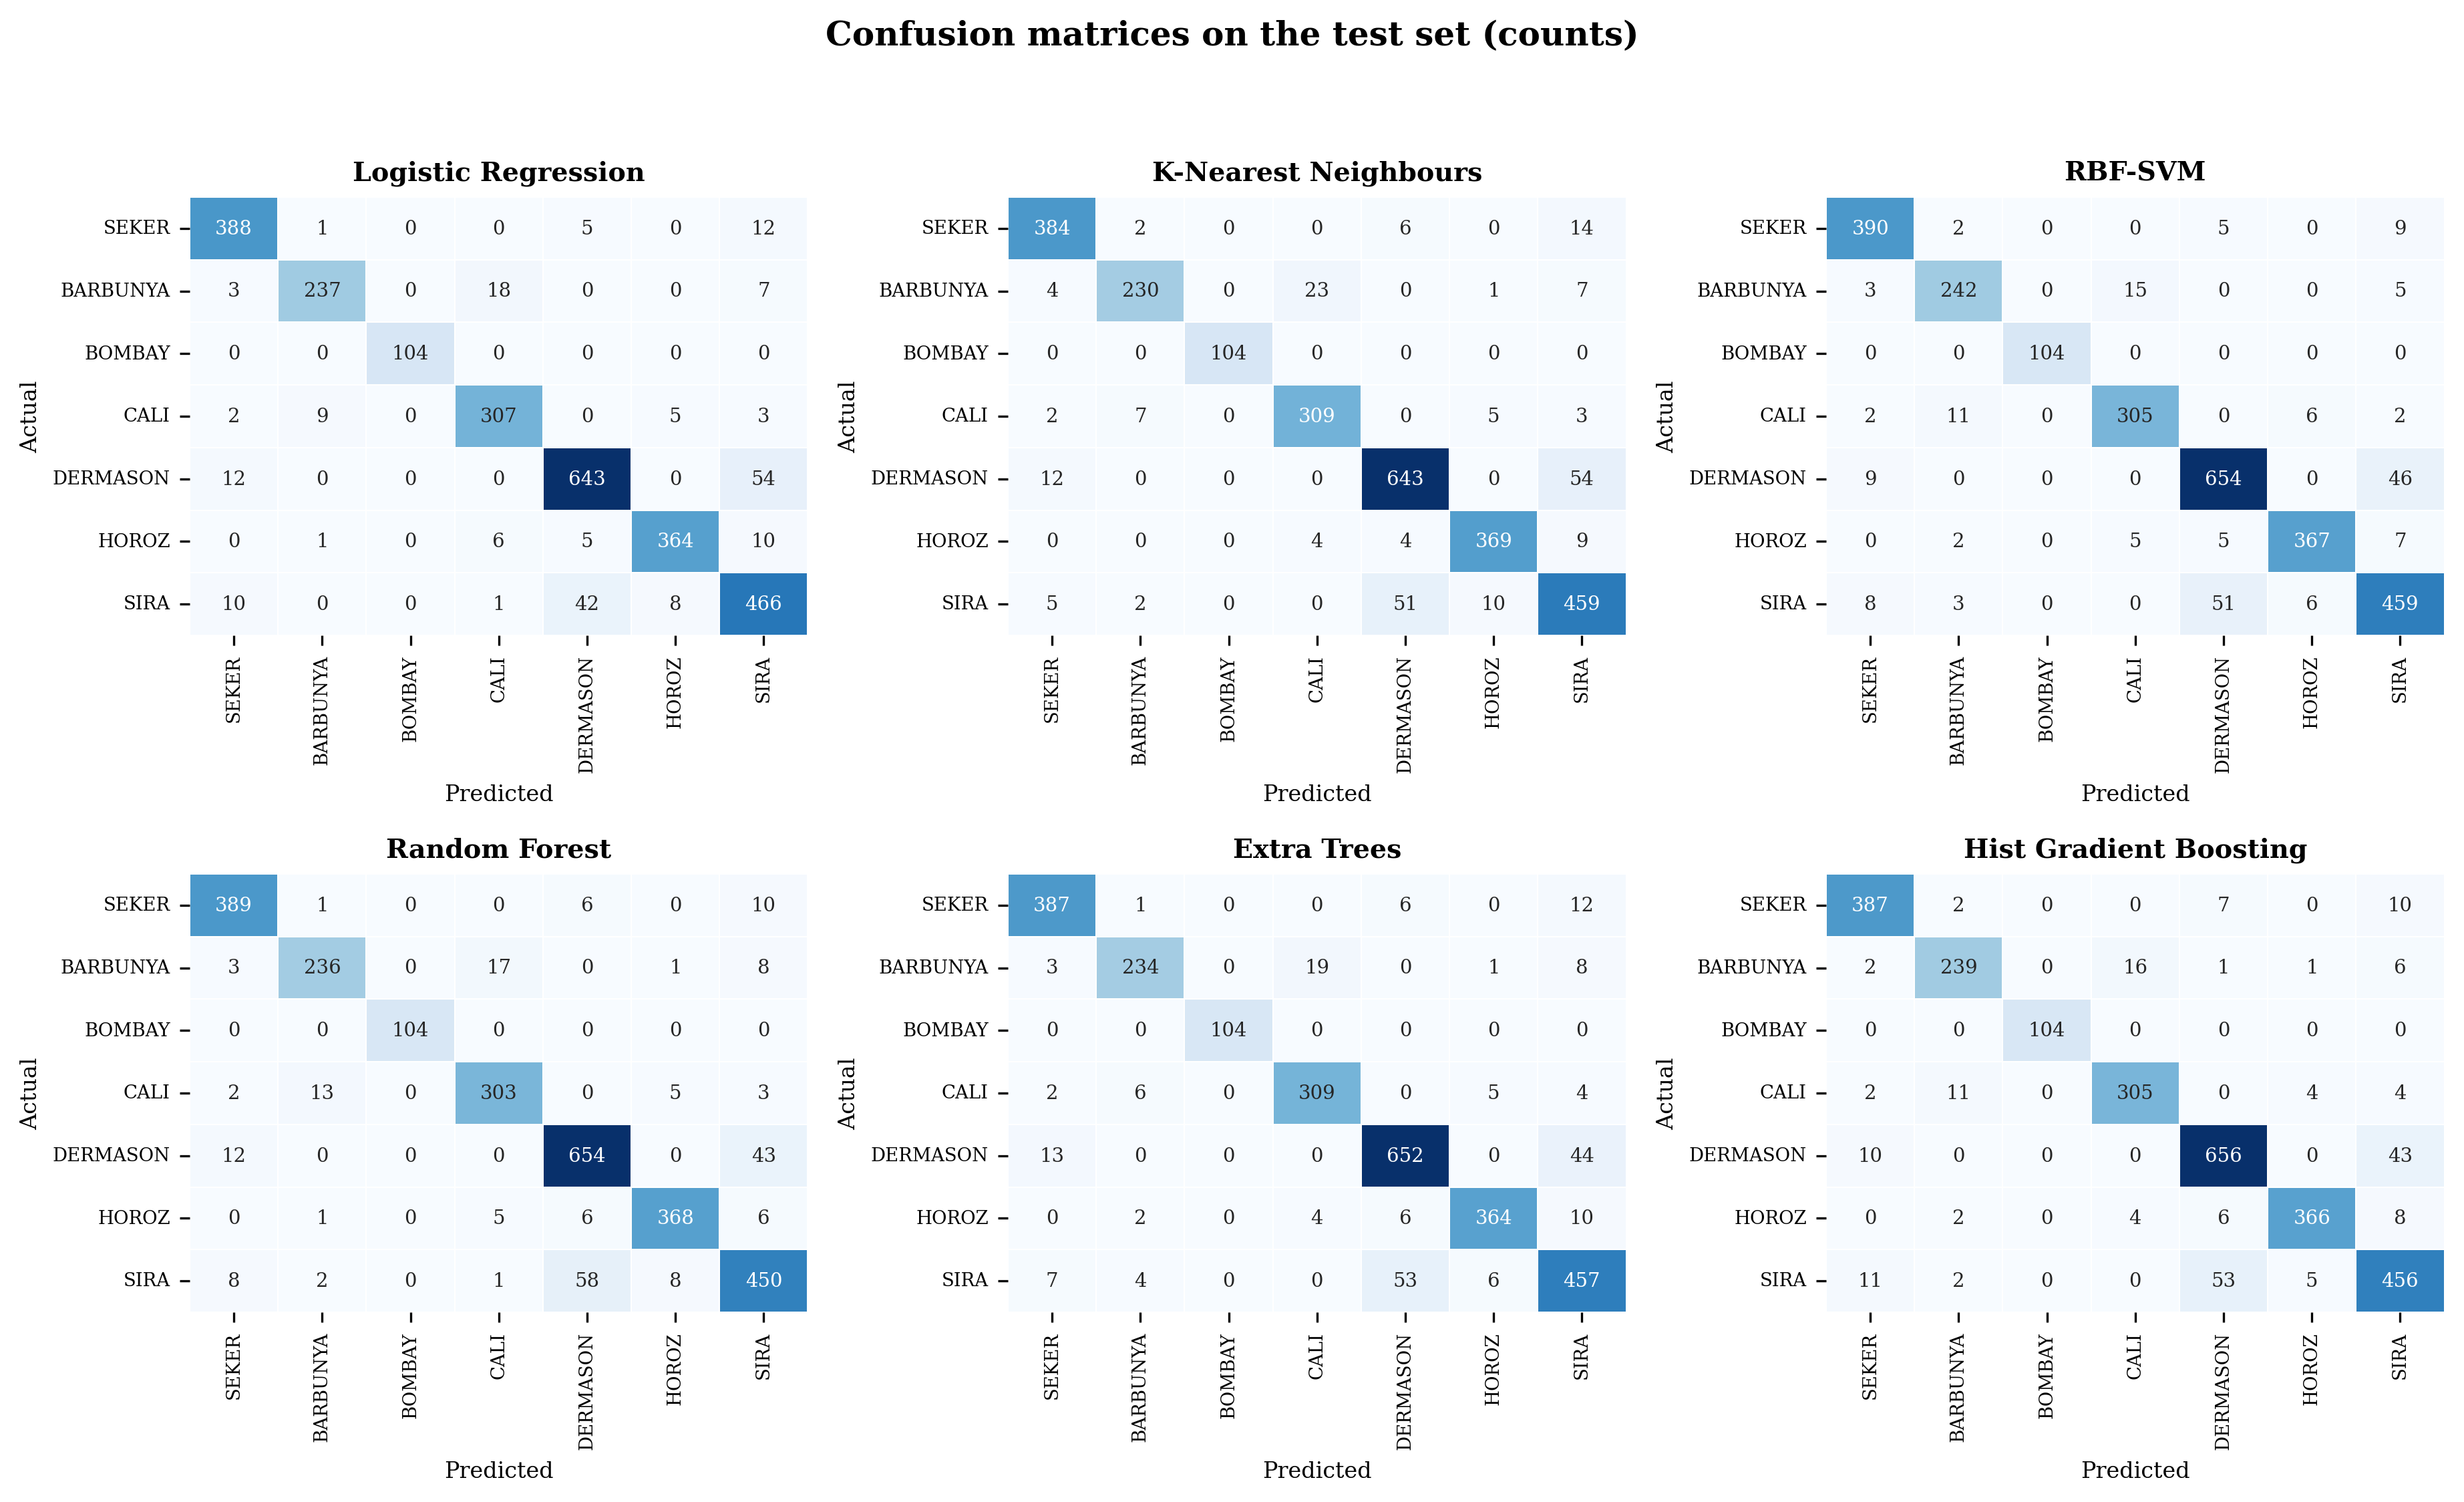

In [6]:
display(Image("figures/evaluation/fig_6_3_confusion_matrix_best.png", width=560))
display(Image("figures/evaluation/fig_6_2_confusion_matrices.png", width=1000))

Nearly all remaining errors are DERMASON beans predicted as SIRA. The
two varieties share an elongated, low-compactness shape, so their feature ranges
overlap even though their mean areas differ.

## 3. ROC curves and error analysis

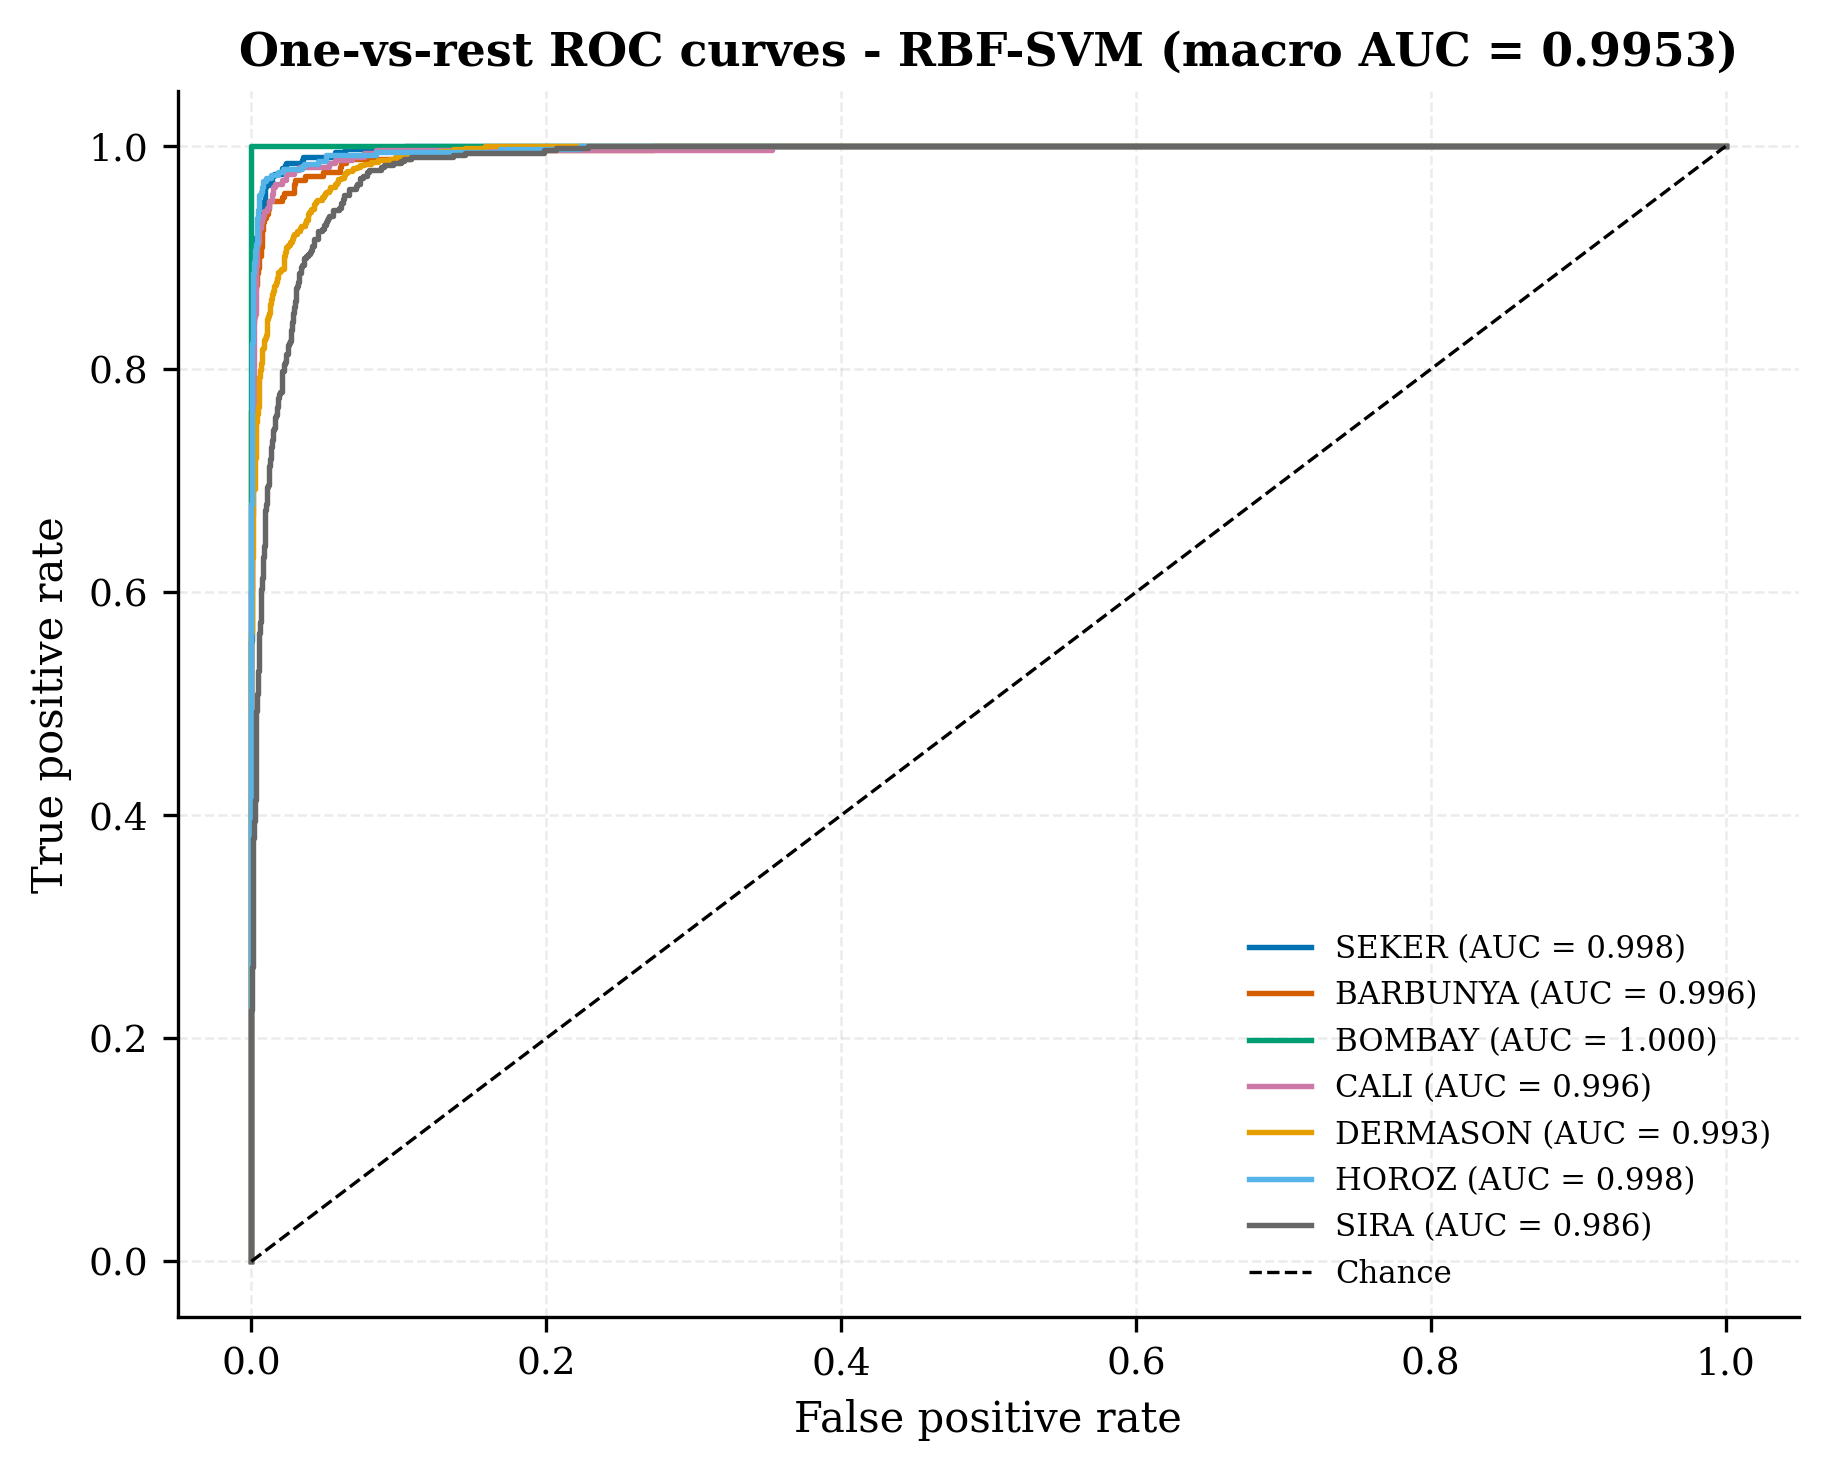

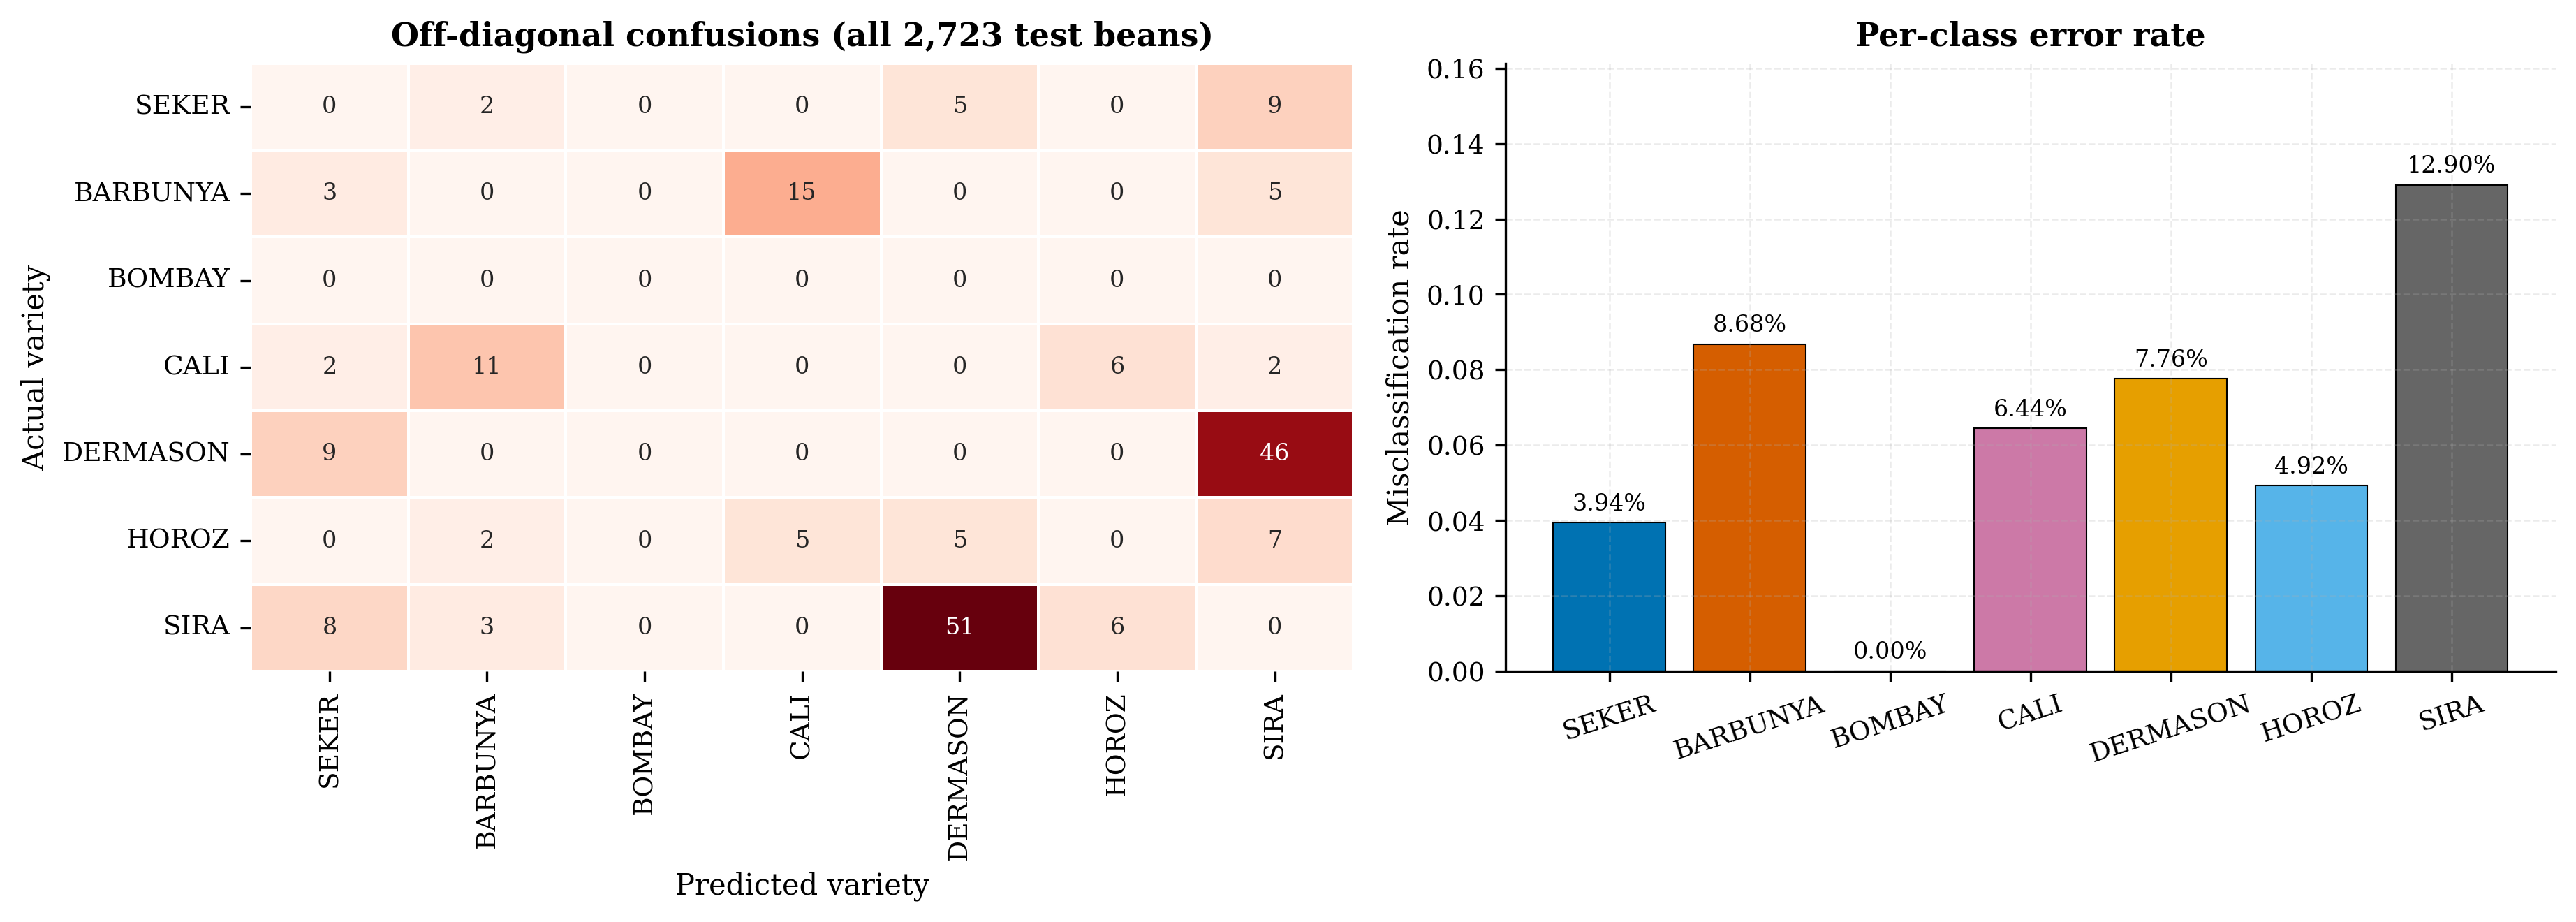

In [7]:
display(Image("figures/evaluation/fig_6_5_roc_curves.png", width=520))
display(Image("figures/evaluation/fig_6_7_error_analysis.png", width=1000))

In [8]:
pd.read_csv("results/metrics/confusion_pairs_best.csv").head(8)

,actual,predicted,count
0,SIRA,DERMASON,51
1,DERMASON,SIRA,46
2,BARBUNYA,CALI,15
3,CALI,BARBUNYA,11
4,SEKER,SIRA,9
5,DERMASON,SEKER,9
6,SIRA,SEKER,8
7,HOROZ,SIRA,7


## 4. Interpretation

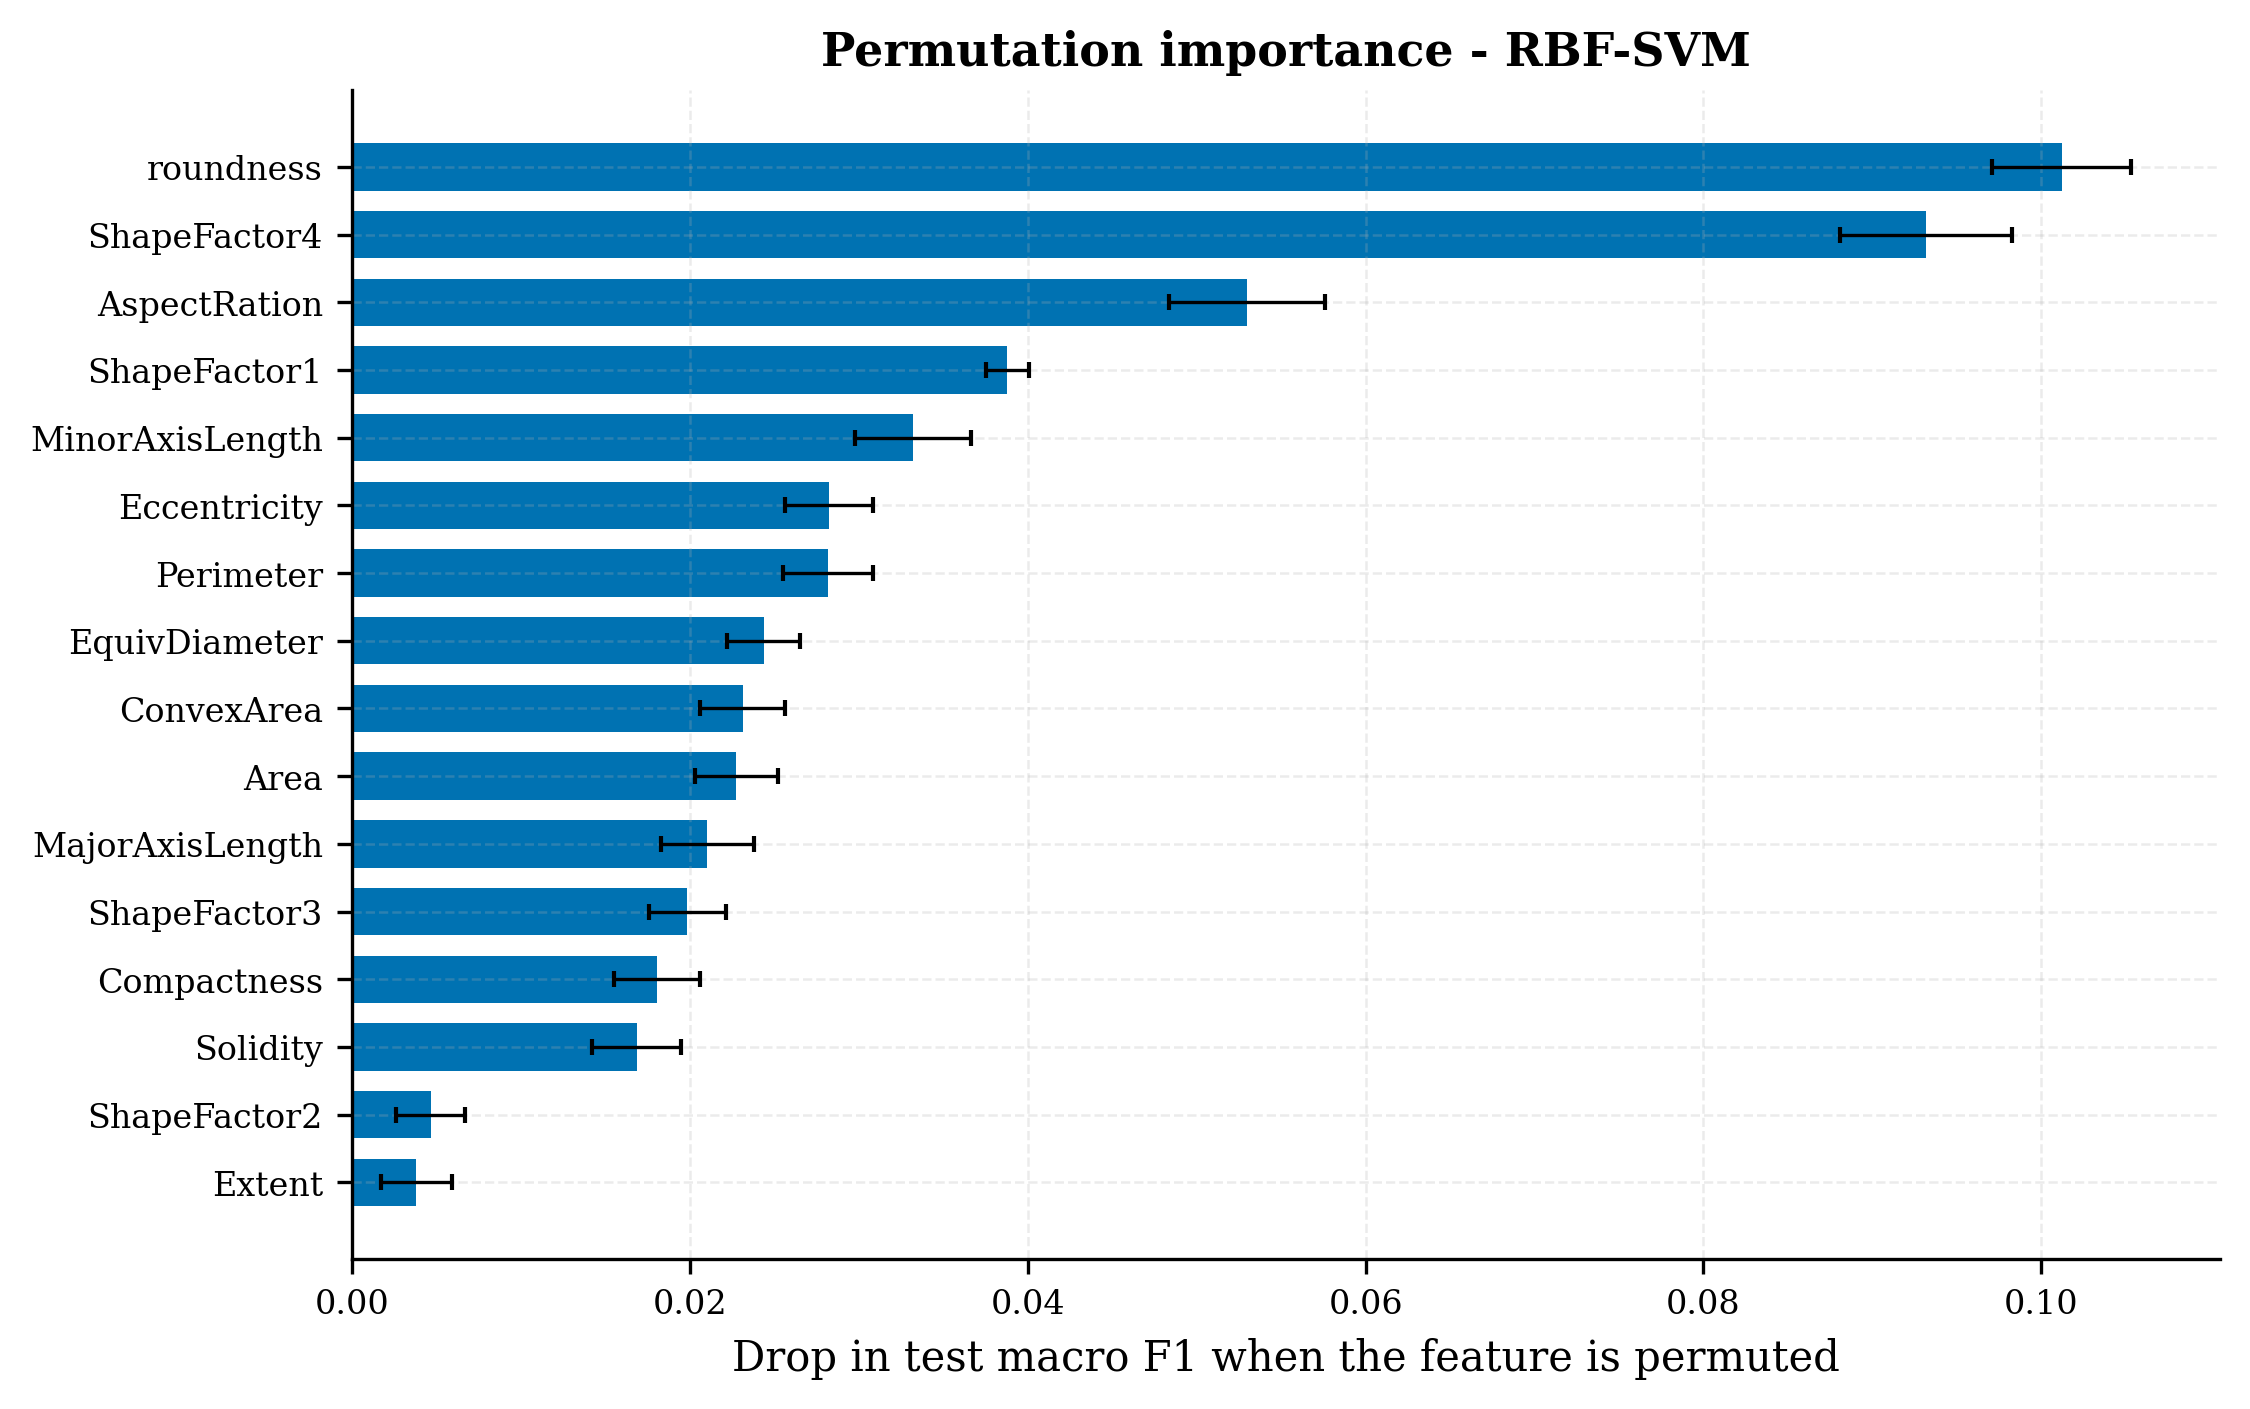

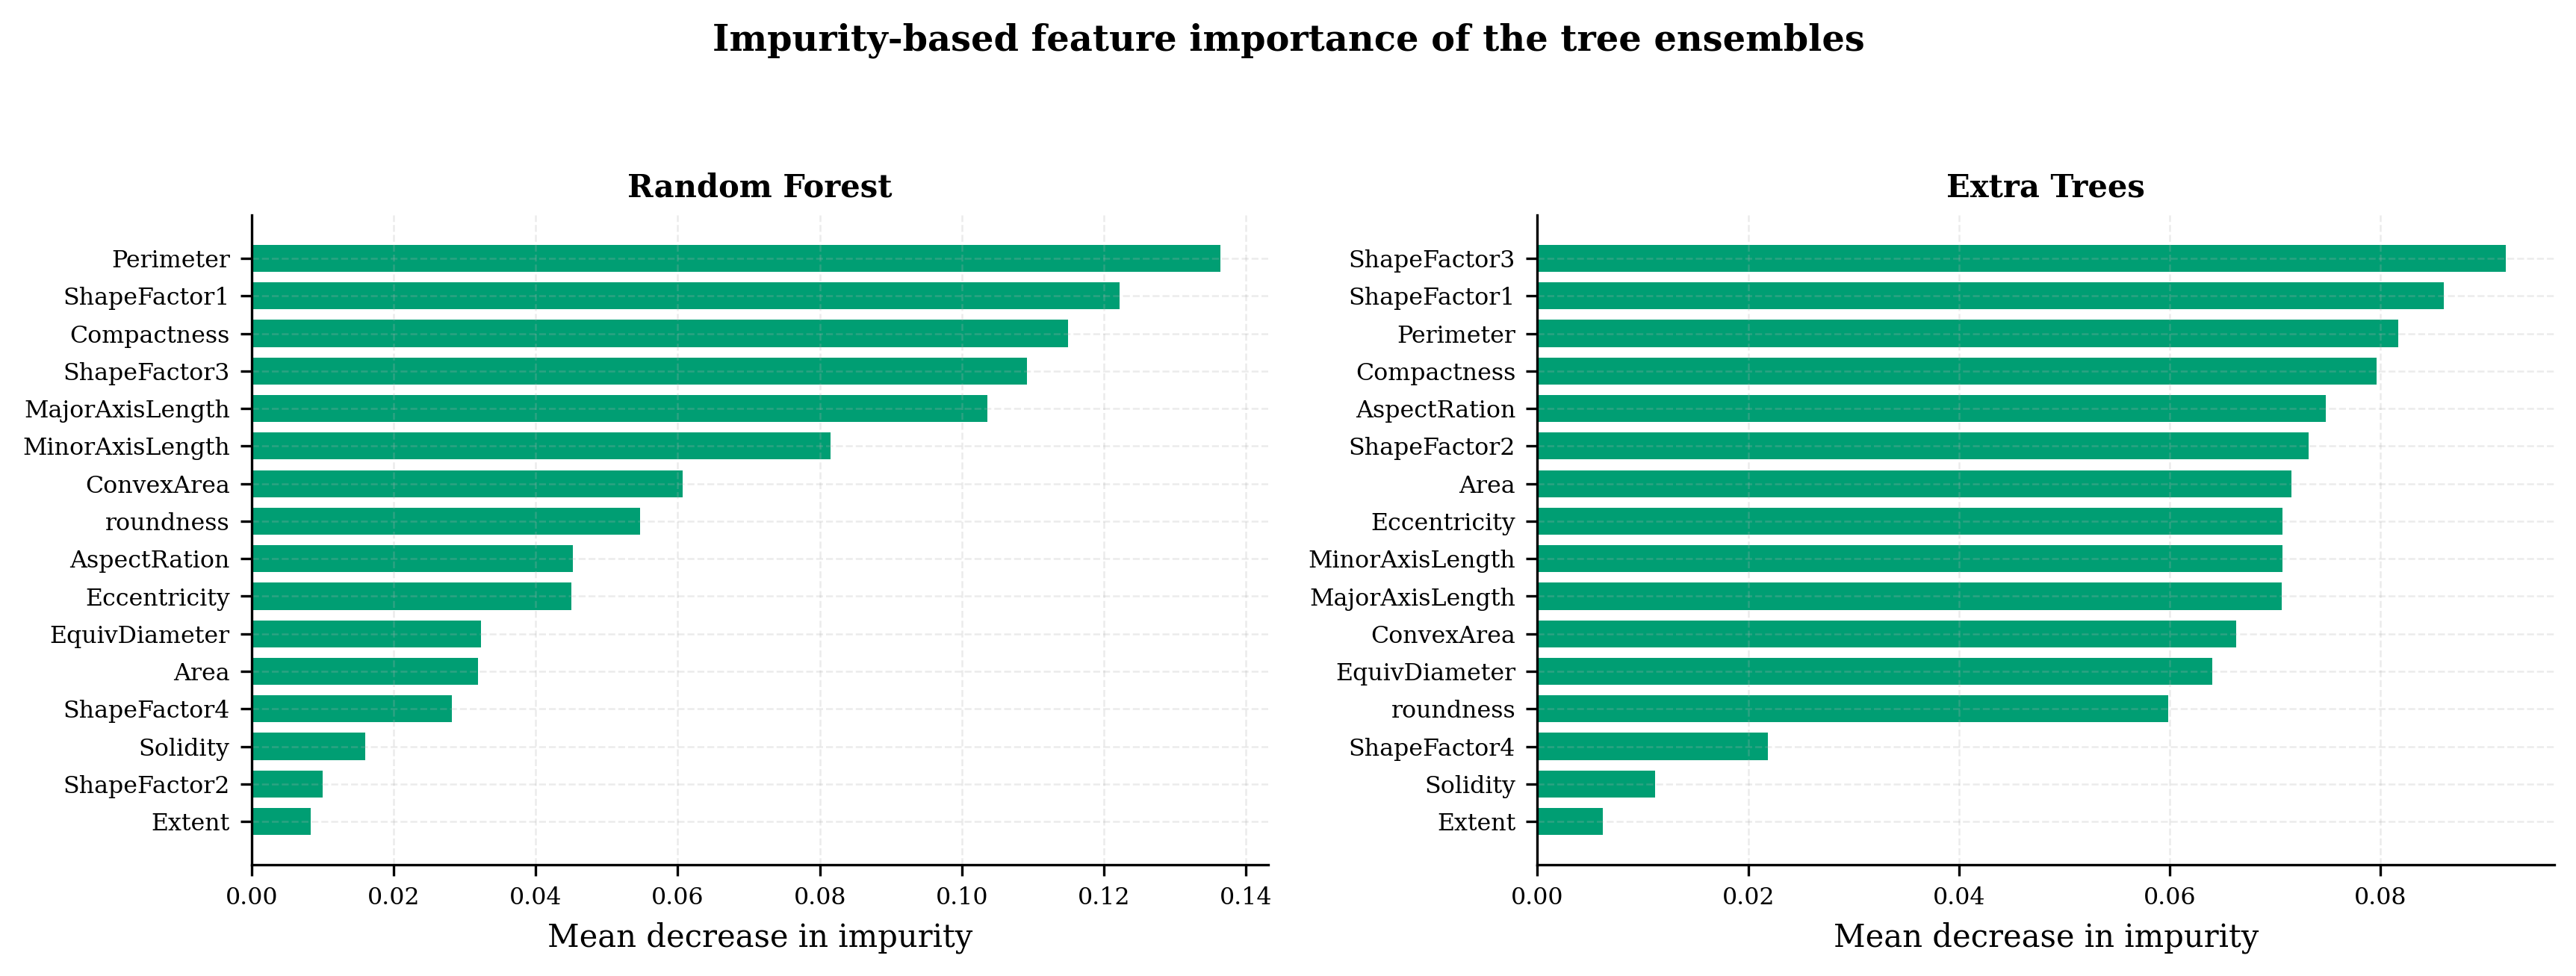

In [9]:
display(Image("figures/evaluation/fig_6_10_permutation_importance.png", width=620))
display(Image("figures/evaluation/fig_6_11_tree_feature_importance.png", width=1000))

`ShapeFactor1` and `Compactness` dominate every importance measure.
Because they are ratios of the size features, they summarise the elongation of a
bean in a scale-free way, which is exactly what separates the five overlapping
varieties.

## 5. Prediction demonstration

In [10]:
from src.predict import predict_records, load_model
model = load_model()
samples = pd.read_csv("results/predictions/sample_predictions.csv")
samples[["actual", "predicted", "correct", "confidence", "runner_up"]]

,actual,predicted,correct,confidence,runner_up
0,SEKER,SEKER,True,0.9943,DERMASON
1,BARBUNYA,BARBUNYA,True,0.9998,SEKER
2,BOMBAY,BOMBAY,True,0.9990,SEKER
3,CALI,CALI,True,0.9867,BARBUNYA
4,DERMASON,DERMASON,True,0.7229,SIRA
5,HOROZ,HOROZ,True,0.9590,SIRA
6,SIRA,SIRA,True,0.9361,DERMASON


In [11]:
from src.config import FEATURES
record = samples.iloc[0]
features = {c: float(record[c]) for c in FEATURES}
for r in predict_records([features], model):
    print("prediction:", r["predicted_variety"], "confidence", r["confidence"])
    for t in r["top3"]:
        print(f"   {t['variety']:<10} {t['probability']:.4f}")

prediction: SEKER confidence 0.9946
   SEKER      0.9946
   DERMASON   0.0030
   SIRA       0.0019


In [12]:
!python -m src.predict --csv results/predictions/sample_predictions.csv

/home/shreyas/.local/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


/home/shreyas/.local/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/shreyas/.local/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


bean 1: SEKER [confidence 0.995] | top-3: SEKER (0.995), DERMASON (0.003), SIRA (0.002)
bean 2: BARBUNYA [confidence 1.000] | top-3: BARBUNYA (1.000), SEKER (0.000), BOMBAY (0.000)
bean 3: BOMBAY [confidence 0.999] | top-3: BOMBAY (0.999), SEKER (0.000), HOROZ (0.000)
bean 4: CALI [confidence 0.986] | top-3: CALI (0.986), BARBUNYA (0.006), BOMBAY (0.005)
bean 5: DERMASON [confidence 0.722] | top-3: DERMASON (0.722), SIRA (0.272), HOROZ (0.005)
bean 6: HOROZ [confidence 0.961] | top-3: HOROZ (0.961), SIRA (0.038), DERMASON (0.001)
bean 7: SIRA [confidence 0.939] | top-3: SIRA (0.939), DERMASON (0.039), HOROZ (0.017)


The command-line interface accepts either a CSV of measurements or all
16 values as flags, and prints the predicted variety with its top-3
probabilities.